# ノッチフィルタ(ツイン T)

ある周波数だけを深く落とし、ほかの周波数はそのまま通す回路です。[バンドパスフィルタ](03_mfb_bpf.ipynb)の逆の働きで、決まった周波数の雑音(例:電源の 50 / 60 Hz のハム)を取り除くのに使います。

この回では、$f_c$ の正弦波を消す、Q を変えたボード線図、方形波から基本の周波数の成分だけを取り除く、の 3 つを見ます。

## 回路

![ツイン T のノッチフィルタ](04_notch/circuit.svg)

T 字形の回路を 2 つ(R、R、2C の T と、C、C、R/2 の T)並べた**ツイン T**(Twin-T)に、ボルテージフォロワをつないだ回路です。2C と R/2 は信号のグランド(Mimic の Vref)につなぎます。

## 原理

上の T(R、R、2C)は LPF、下の T(C、C、R/2)は HPF のように働きます。$f_c$ ではちょうど、2 つの経路を通った信号の大きさが等しく、向きが逆になり、打ち消し合って出力が 0 になります。

Mimic のノッチフィルタは、次の形です。

$$H(f) = \frac{1 - (f/f_c)^2}{1 - (f/f_c)^2 + j\,\dfrac{f/f_c}{Q}}, \qquad f_c = \frac{1}{2\pi R C}$$

| 周波数 | 振幅 | 位相 |
|---|---|---|
| $f \ll f_c$ | 1 | 0° |
| $f = f_c$ | **0** | ±90° で入れ替わる |
| $f \gg f_c$ | 1 | 0° |

落とす幅(−3 dB の幅)は $f_c / Q$ です。Q が大きいほど、$f_c$ のごく近くだけを落とします。

ツイン T だけの回路では Q = 1/4 と小さく、まわりの周波数まで落としてしまいます。出力を 2C と R/2 の側へ戻す(ブートストラップ)と、Q を大きくできます。

![ノッチフィルタの周波数特性(模式図)](04_notch/response.svg)

ノッチフィルタの出力は「入力 − バンドパスフィルタの出力」になっています($H_\mathrm{notch} = 1 - H_\mathrm{BPF}$)。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.biquad_notch(fc, q)` | `mimic.setFilterBiquadNotch(fc, Q)` | $f_c = \dfrac{1}{2\pi R C}$(ツイン T だけなら $Q = 1/4$) |

例:$f_c$ = 100 Hz は、R = 16 kΩ、C = 0.1 µF(R/2 = 8 kΩ、2C = 0.2 µF)の回路にあたります。Mimic では Q も直接設定できます(0.1〜10)。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, Monitor, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

In [2]:
FC = 100  # notch frequency [Hz]

def bode_axes(title):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax1.set_title(title)
    ax1.set_ylabel("Gain [dB]")
    ax2.set_ylabel("Phase [deg]")
    ax2.set_xlabel("Frequency [Hz]")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.4)
    return fig, ax1, ax2


def second_order(f, fc, q, kind):
    # Response of the module: lpf 1/D, hpf s^2/D, bpf (s/Q)/D, notch (s^2 + 1)/D
    s = 1j * f / fc
    d = s * s + s / q + 1
    return {"lpf": 1, "hpf": s * s, "bpf": s / q, "notch": s * s + 1}[kind] / d

## 実験 1:$f_c$ の正弦波を消す

Q = 5 にして、$f_c$(100 Hz)と、少しずらした 80 Hz の正弦波を入れます。100 Hz はほとんど消え、80 Hz はほぼそのまま残るはずです。

100 Hz: gain 0.024 (theory 0.000)
80 Hz: gain 0.918 (theory 0.914)


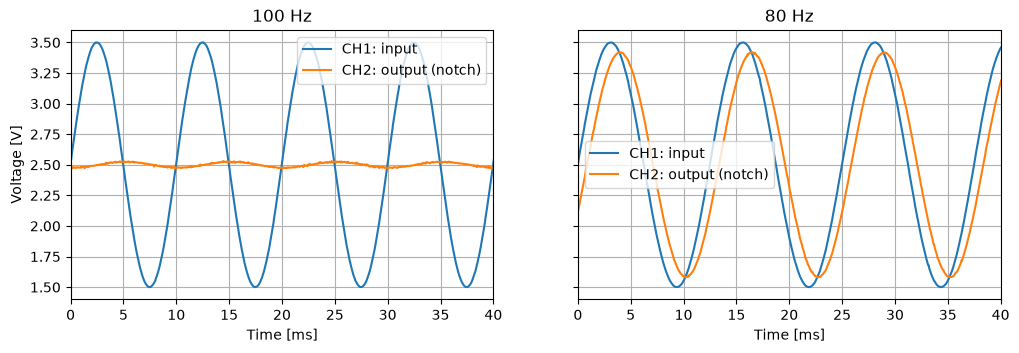

In [3]:
import time

lab.mimic.biquad_notch(FC, 5)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, f in zip(axes, [FC, 80]):
    lab.fg.sine(f, 1.0)
    time.sleep(0.3)  # wait for the filter to settle
    t, ch1, ch2 = lab.scope.capture(2000)
    a1, p1, c1 = fit_sine(t, ch1, f)
    a2, p2, c2 = fit_sine(t, ch2, f)
    h = second_order(f, FC, 5, "notch")
    print(f"{f} Hz: gain {a2 / a1:.3f} (theory {abs(h):.3f})")
    ax.plot(t * 1e3, ch1, label="CH1: input")
    ax.plot(t * 1e3, ch2, label="CH2: output (notch)")
    ax.set_title(f"{f} Hz")
    ax.set_xlim(0, 40)
    ax.set_xlabel("Time [ms]")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("Voltage [V]")
plt.show()

## 実験 2:Q を変えたボード線図

Q = 0.25(ツイン T だけの回路と同じ)、1、5 で、$f_c$ のまわりを細かく測ります。

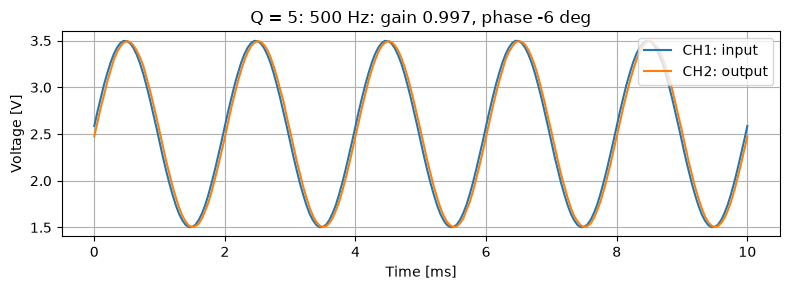

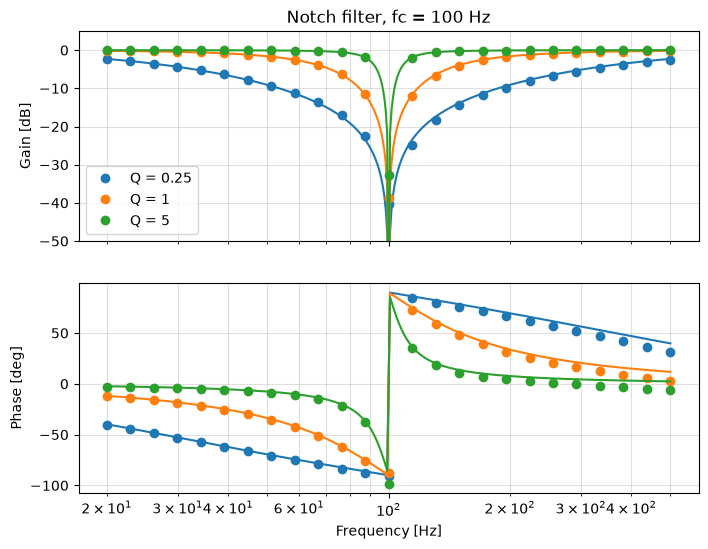

In [4]:
freqs = np.logspace(np.log10(20), np.log10(500), 25)   # 20 - 500 Hz
f_th = np.logspace(np.log10(20), np.log10(500), 401)
fig, ax1, ax2 = bode_axes(f"Notch filter, fc = {FC} Hz")
rs = {}
mon = Monitor()  # one plot updated while measuring
for i, q in enumerate([0.25, 1, 5]):
    lab.mimic.biquad_notch(FC, q)
    r = rs[q] = lab.frequency_response(freqs, monitor=mon, label=f"Q = {q}: ")
    h = second_order(f_th, FC, q, "notch")
    ax1.semilogx(f_th, 20 * np.log10(np.maximum(abs(h), 1e-4)), "-", color=f"C{i}")
    ax2.semilogx(f_th, np.degrees(np.angle(h)), "-", color=f"C{i}")
    ax1.semilogx(r.freq, r.gain_db, "o", color=f"C{i}", label=f"Q = {q}")
    ax2.semilogx(r.freq, match_phase(r.phase, np.degrees(np.unwrap(np.angle(second_order(r.freq, FC, q, "notch"))))), "o", color=f"C{i}")
ax1.set_ylim(-50, 5)
ax1.legend()
mon.close()
plt.show()

各周波数で取り込んだ波形です(クリックで開きます)。


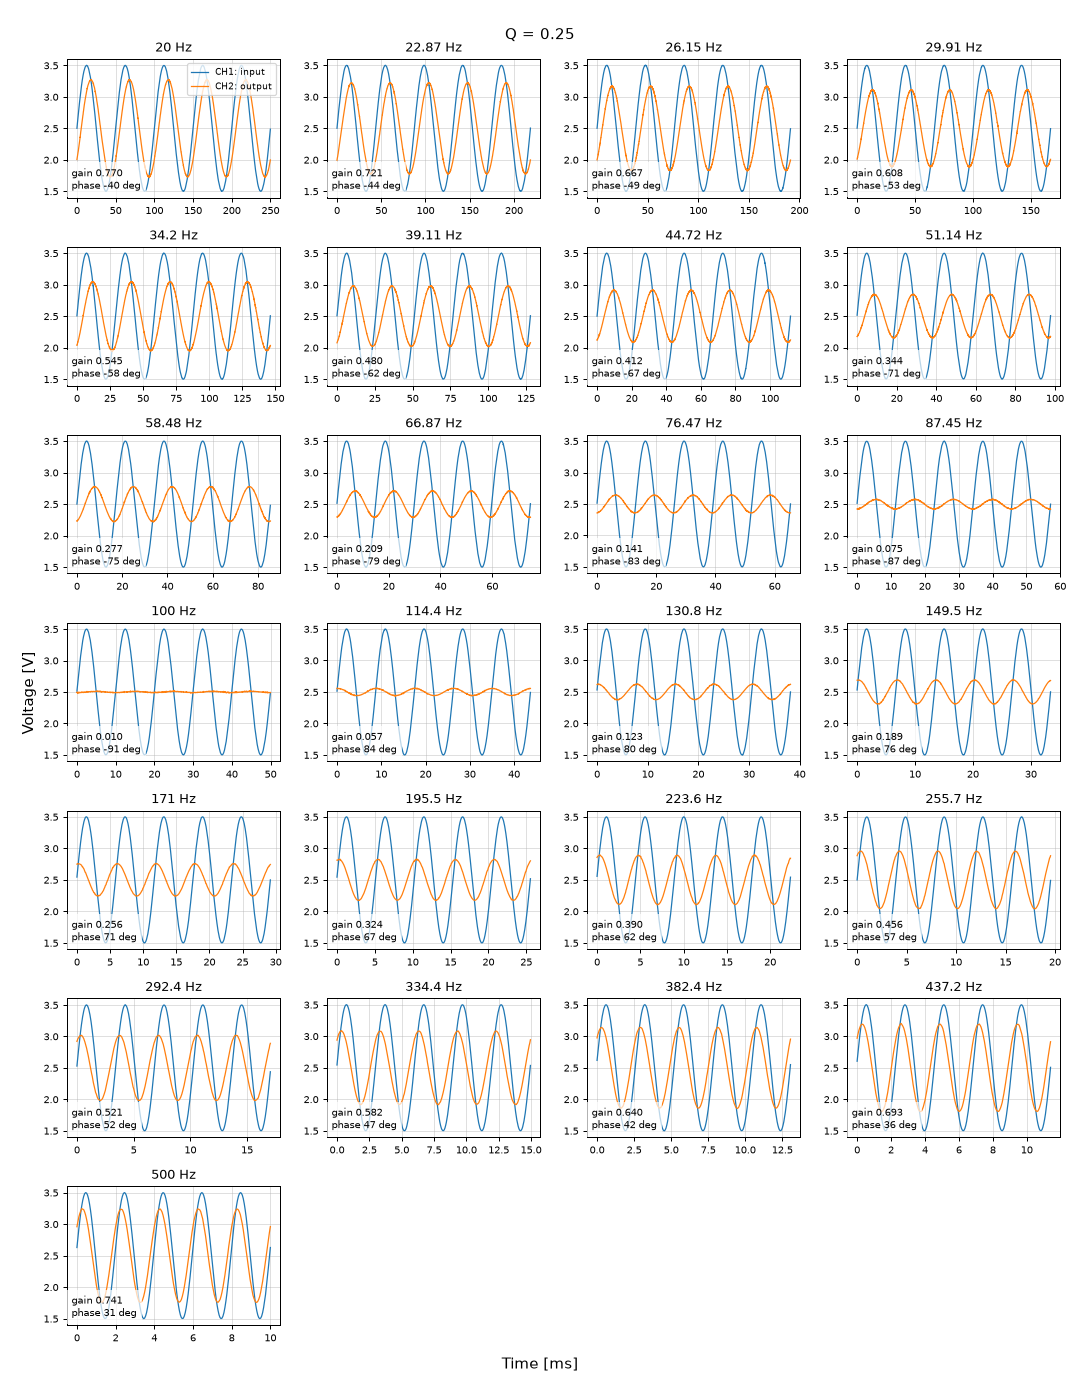


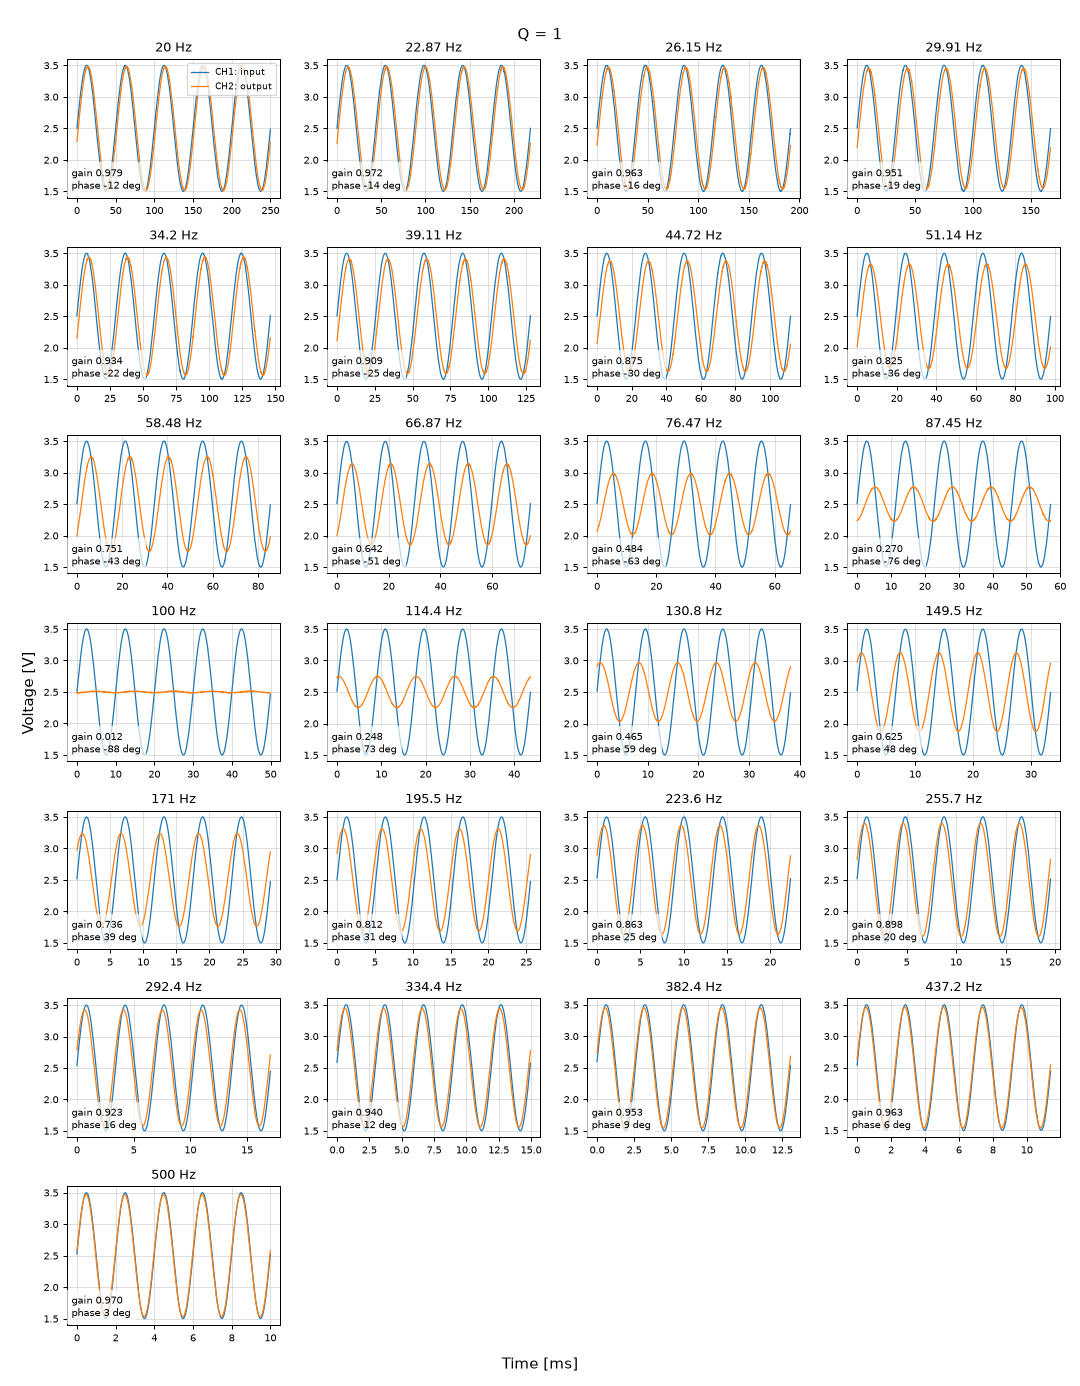


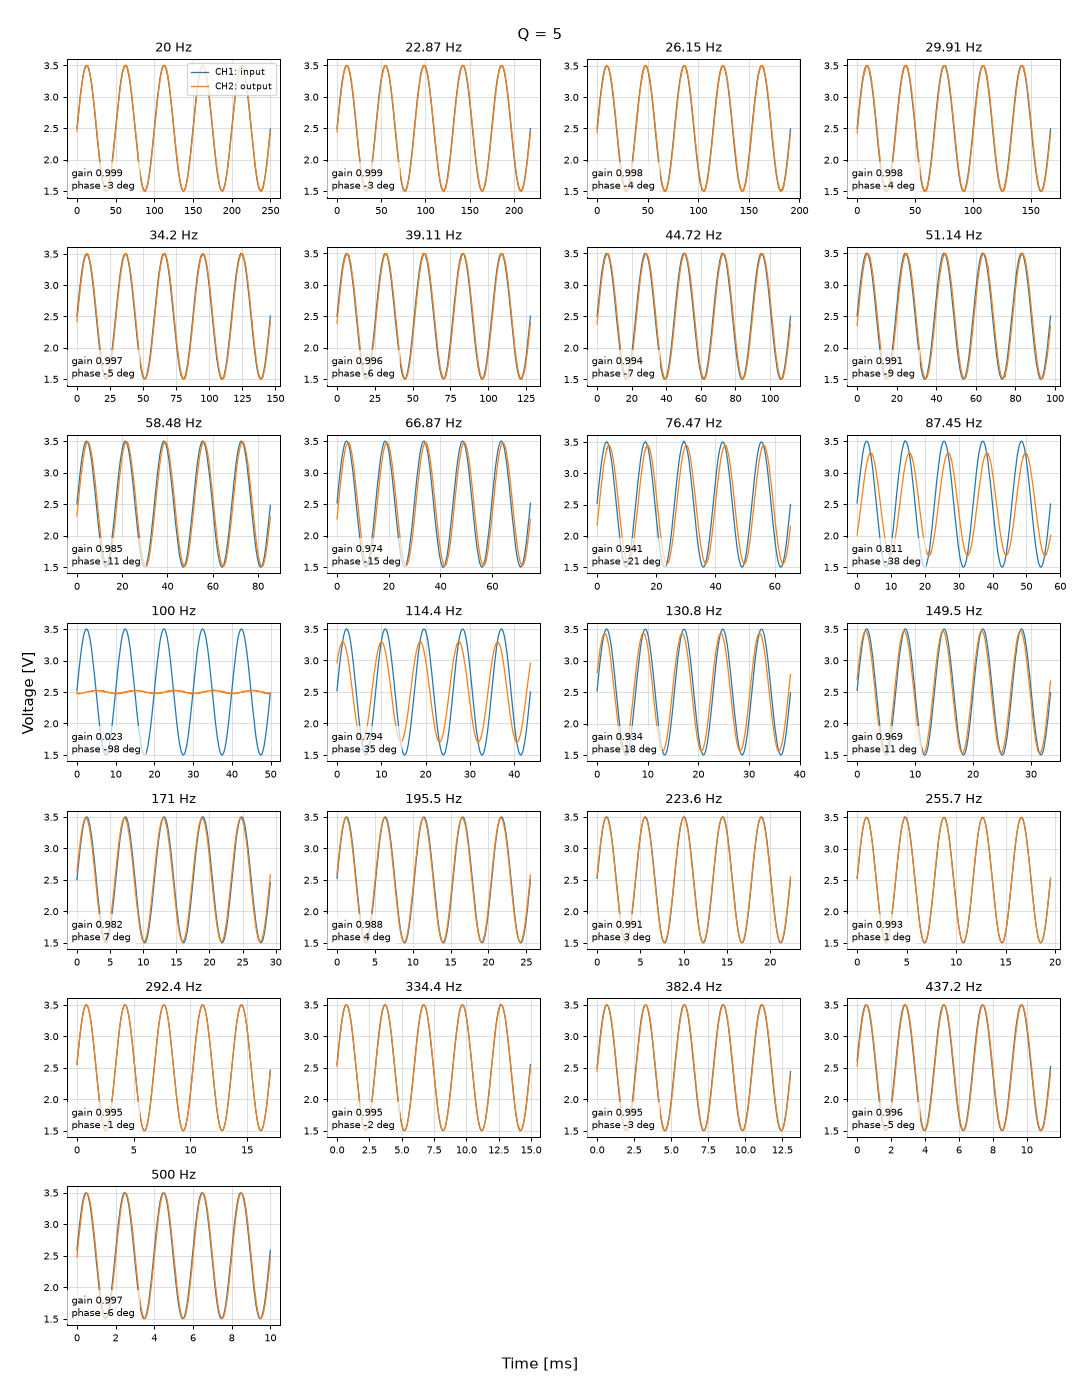

In [5]:
for key, r in rs.items():
    plot_waveforms(r, title=f"Q = {key}", collapsed=True)

いちばん深いところは、測定点がちょうど $f_c$ に乗らないことと、測定の雑音で、理論ほど深くはなりません。

## 実験 3:方形波から基本の周波数を取り除く

100 Hz の方形波は、100 Hz の正弦波と、300 Hz、500 Hz、… の正弦波の重ね合わせです([バンドパスフィルタの回](03_mfb_bpf.ipynb))。$f_c$ = 100 Hz、Q = 5 のノッチフィルタに入れると、100 Hz の成分だけが消え、残りの成分が見えます。

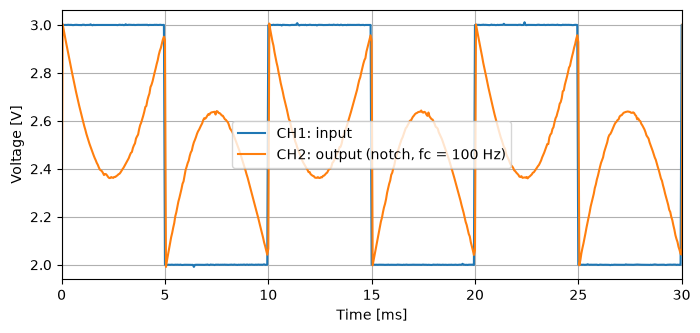

100 Hz component: input 0.637 V, output 0.014 V
300 Hz component: input 0.212 V, output 0.211 V


In [6]:
lab.fg.square(100, 0.5)
lab.mimic.biquad_notch(FC, 5)
time.sleep(0.3)  # wait for the filter to settle
t, ch1, ch2 = lab.scope.capture(2000)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (notch, fc = 100 Hz)")
ax.set_xlim(0, 30)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

for f in [100, 300]:
    a1, _, _ = fit_sine(t, ch1, f)
    a2, _, _ = fit_sine(t, ch2, f)
    print(f"{f} Hz component: input {a1:.3f} V, output {a2:.3f} V")

100 Hz の成分はほとんど 0 になり、300 Hz の成分はそのまま残ります。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 消す周波数を変える

100 Hz の方形波から、ノッチフィルタで成分を 1 つ消します。波形はどう変わるでしょうか。
<details><summary>ヒント</summary>

`F_NOTCH` を 100 → 300 → 500 と変えてみましょう。消した成分だけが 0 に近くなり、ほかの成分は残ります。300 Hz を消すと、方形波の平らな部分に小さなうねりが出ます。

</details>

100 Hz component: input 0.637 V, output 0.635 V
300 Hz component: input 0.212 V, output 0.009 V
500 Hz component: input 0.127 V, output 0.124 V


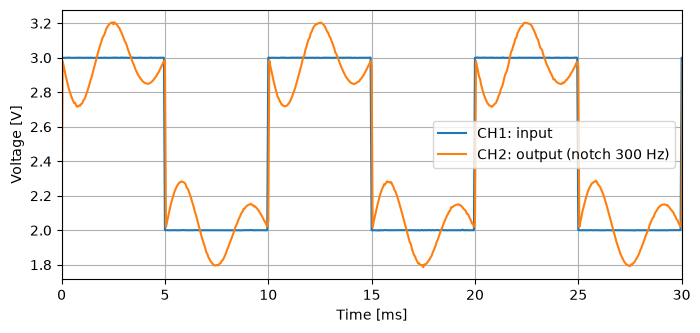

In [7]:
F_NOTCH = 300   # [Hz]

import time
lab.fg.square(100, 0.5)
lab.mimic.biquad_notch(F_NOTCH, 5)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)
for f in [100, 300, 500]:
    a1, _, _ = fit_sine(t, ch1, f)
    a2, _, _ = fit_sine(t, ch2, f)
    print(f"{f} Hz component: input {a1:.3f} V, output {a2:.3f} V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (notch {F_NOTCH} Hz)")
ax.set_xlim(0, 30)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. Q を変えて、となりの周波数の残り方を見る

80 Hz の正弦波を、$f_c$ = 100 Hz のノッチフィルタに入れて、Q を変えます。
<details><summary>ヒント</summary>

`Q_TRY` を 0.25 → 1 → 5 と変えてみましょう。ゲインは 0.11、0.41、0.91 です。消したい周波数のまわりを残したいときは、Q を大きくします。ただし Q が大きいと、消したい周波数が少しずれただけで消えなくなります(`FREQ` を 98 Hz などにして試せます)。

</details>

Q = 0.25, 80 Hz: gain 0.119 (theory 0.112)


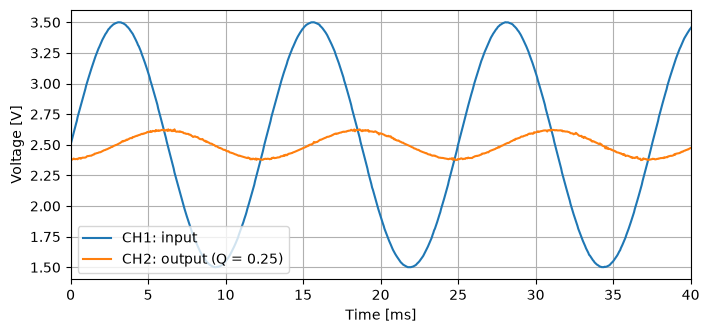

In [8]:
Q_TRY = 0.25
FREQ = 80   # [Hz]

import time
lab.mimic.biquad_notch(FC, Q_TRY)
lab.fg.sine(FREQ, 1.0)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)
a1, _, _ = fit_sine(t, ch1, FREQ)
a2, _, _ = fit_sine(t, ch2, FREQ)
print(f"Q = {Q_TRY}, {FREQ} Hz: gain {a2 / a1:.3f} (theory {abs(second_order(FREQ, FC, Q_TRY, 'notch')):.3f})")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (Q = {Q_TRY})")
ax.set_xlim(0, 40)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- ノッチフィルタは $f_c$ だけを深く落とす。落とす幅は $f_c / Q$。
- ツイン T 回路は、$f_c = 1/(2\pi RC)$ で 2 つの経路の信号が打ち消し合う。そのままでは Q = 1/4。
- ノッチフィルタ = 入力 − バンドパスフィルタ。Mimic では `biquad_notch(fc, q)`。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()